# Soft-DTW: a Differentiable Loss Function for Time-Series
Mini-project, *Machine Learning for Time Series* (MVA). Paper: M. Cuturi and M. Blondel, ICML 2017.
Pablo Borrego, Pol Tibau.

The notebook follows the report:
1. **Method**: our implementation of soft-DTW (Algorithms 1 and 2) and of our extension soft-DTW$_\omega$, and their verification.
2. **Data**: the 13 UCR datasets and the data diagnosis.
3. **Experiments**: the four experiments of the paper (barycenters, $k$-means, nearest centroid, forecasting), with soft-DTW$_\omega$ added to each of them.
4. **Conclusion**.

**Code.** Everything is implemented from scratch in the repository; `tslearn` is only used to load the UCR data, for the DBA baseline and as a numerical cross-check.

| File | Content |
|---|---|
| `softdtw.py` | soft-DTW forward/backward (Numba), gradient, hard DTW and its path |
| `softdp.py` | generic soft dynamic program with per-step costs: soft-DTW and soft-DTW$_\omega$ |
| `torch_sdtw.py`, `torch_sdtw_diag.py` | PyTorch losses (custom backward; anti-diagonal GPU-ready version) |
| `barycenter.py`, `omega.py`, `clustering.py` | barycenters (soft-DTW, soft-DTW$_\omega$, DBA, subgradient), $k$-means, nearest centroid |
| `exp_*.py` | one script per experiment, writing `results/*.csv` |
| `tests.py`, `tests_softdp.py` | test-suite |

**Running time.** Sections 1 and 2 run in about a minute. The experiments take hours on a laptop, so Section 3 **reads the saved results** in `results/` and rebuilds the tables of the report from them; the script that produced each file is given in each section and can be re-run (it resumes from its checkpoints).

In [1]:
import subprocess, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from softdtw import (sdtw_forward, sdtw_backward, soft_dtw, soft_dtw_alignment,
                     soft_dtw_value_and_grad, dtw, dtw_path, sqeuclidean_cost)
from softdp import edge_costs, soft_dp, soft_distance, expected_warps

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
rng = np.random.default_rng(0)
GAMMAS = [1.0, 0.1, 0.01, 0.001]

## 1. Method

### 1.1 A worked example of Algorithms 1 and 2
Cost matrix $\Delta = \begin{pmatrix}1&3\\2&1\end{pmatrix}$ and $\gamma=1$. There are three alignments: the diagonal one (cost $1+1=2$), the one through $(2,1)$ (cost $1+2+1=4$) and the one through $(1,2)$ (cost $1+3+1=5$).
So $\mathrm{dtw}_\gamma = -\log(e^{-2}+e^{-4}+e^{-5})$, and the backward pass must return $E$ = the probability, under the Gibbs distribution $p(A)\propto e^{-\langle A,\Delta\rangle/\gamma}$, that the path visits each cell.

In [2]:
D = np.array([[1.0, 3.0], [2.0, 1.0]])
R = sdtw_forward(D, 1.0)          # Algorithm 1 (R has a border row/column of +inf)
E = sdtw_backward(D, R, 1.0)      # Algorithm 2
p = np.exp(-np.array([2.0, 4.0, 5.0])); p /= p.sum()
print("dtw_gamma from the recursion :", R[2, 2])
print("dtw_gamma from the definition:", -np.log(np.exp(-2) + np.exp(-4) + np.exp(-5)), "  (hard DTW = 2)")
print("E =\n", E.round(4))
print("Gibbs probabilities of the 3 paths (diagonal, via (2,1), via (1,2)):", p.round(4))
print("e_21 = p(via (2,1)) =", p[1].round(4), "   e_12 = p(via (1,2)) =", p[2].round(4))

dtw_gamma from the recursion : 1.8301539804437146
dtw_gamma from the definition: 1.8301539804437144   (hard DTW = 2)
E =
 [[1.     0.042 ]
 [0.1142 1.    ]]
Gibbs probabilities of the 3 paths (diagonal, via (2,1), via (1,2)): [0.8438 0.1142 0.042 ]
e_21 = p(via (2,1)) = 0.1142    e_12 = p(via (1,2)) = 0.042


### 1.2 Verification
The test-suite checks, among others:
* the value and $E$ against **brute-force enumeration of every alignment** (all Delannoy paths) for $n,m\le5$ and $\gamma\in[10^{-2},10]$;
* the gradient against **finite differences**;
* the bound $\mathrm{dtw}-\gamma\log|\mathcal A_{n,m}|\le\mathrm{dtw}_\gamma\le\mathrm{dtw}$ (so $\gamma\to0$ recovers DTW) and $E\to A^\star$;
* the agreement with `tslearn`;
* the PyTorch custom backward against plain autograd, and the anti-diagonal version against the Numba one;
* for soft-DTW$_\omega$: brute force with step costs, the limits $\omega=0$ (soft-DTW) and $\omega\to\infty$ (Euclidean), and $\partial/\partial\omega$ = expected number of warping steps.

In [3]:
r = subprocess.run([sys.executable, "-m", "pytest", "tests.py", "tests_softdp.py", "-q",
                    "--color=no", "-p", "no:cacheprovider"], capture_output=True, text=True)
print(r.stdout.strip().splitlines()[-1])

67 passed in 12.57s


### 1.3 The expected alignment $E$
Two noisy bumps, the second one shifted in time. For small $\gamma$, $E$ is the DTW path (white); as $\gamma$ grows it spreads over many alignments, and for large $\gamma$ it is pulled towards the diagonal whatever the data (report, Fig. 2 in the appendix).

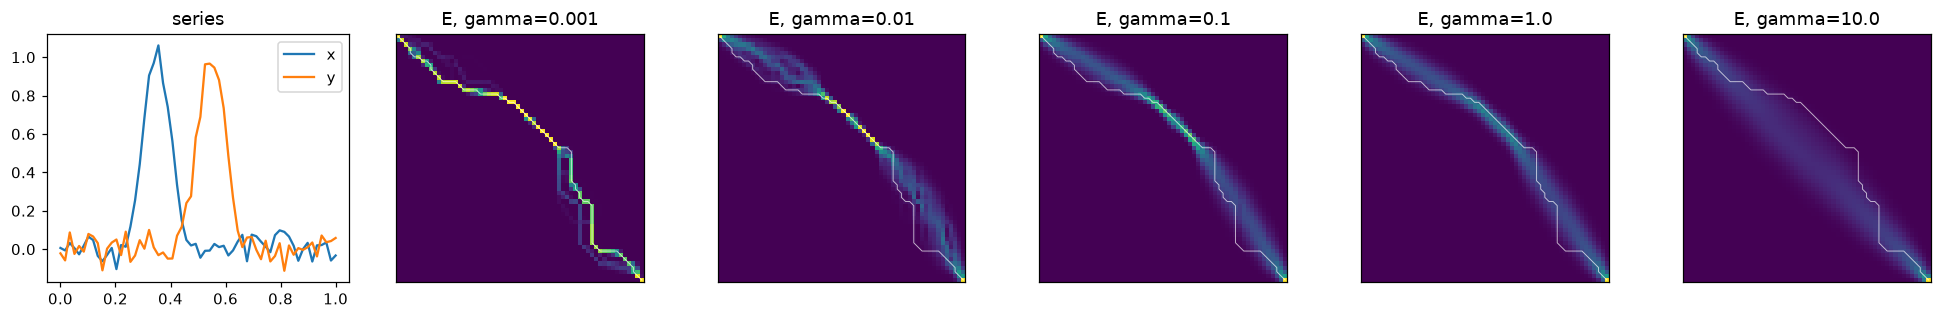

In [4]:
t = np.linspace(0, 1, 60)
x = np.exp(-((t - 0.35) / 0.07) ** 2) + 0.05 * rng.normal(size=t.size)
y = np.exp(-((t - 0.55) / 0.07) ** 2) + 0.05 * rng.normal(size=t.size)
A, _ = dtw_path(x, y)

gammas = [0.001, 0.01, 0.1, 1.0, 10.0]
fig, axes = plt.subplots(1, len(gammas) + 1, figsize=(3 * (len(gammas) + 1), 3))
axes[0].plot(t, x, label="x"); axes[0].plot(t, y, label="y"); axes[0].legend(); axes[0].set_title("series")
for ax, g in zip(axes[1:], gammas):
    _, E = soft_dtw_alignment(x, y, g)
    ax.imshow(E, cmap="viridis", origin="upper")
    ii, jj = np.nonzero(A)
    ax.plot(jj, ii, "w-", lw=0.6, alpha=0.7)
    ax.set_title(f"E, gamma={g}"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig("figures/E_vs_gamma.png", dpi=200); plt.show()

### 1.4 Computational cost
Forward + backward of our Numba implementation, of the same code in pure Python, and of a cell-by-cell PyTorch forward differentiated by autograd. All are $O(nm)$; the constants differ by orders of magnitude, which is why the paper insists on a hand-written backward.

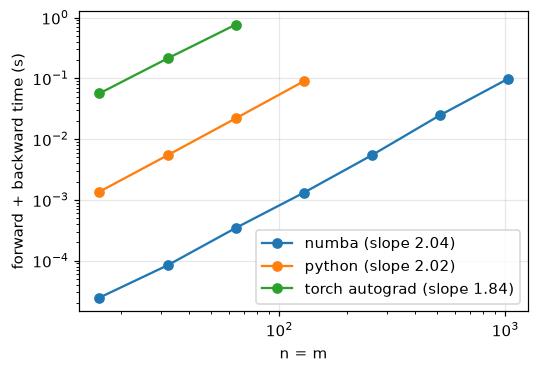

numba {16: np.float64(2e-05), 32: np.float64(8e-05), 64: np.float64(0.00034), 128: np.float64(0.00131), 256: np.float64(0.00541), 512: np.float64(0.02454), 1024: np.float64(0.09752)}
python {16: np.float64(0.00137), 32: np.float64(0.00543), 64: np.float64(0.02188), 128: np.float64(0.08915)}
torch autograd {16: np.float64(0.05665), 32: np.float64(0.21254), 64: np.float64(0.76331)}


In [5]:
import torch
from torch_sdtw import soft_dtw_torch_naive

fwd_py, bwd_py = sdtw_forward.py_func, sdtw_backward.py_func  # same code, not compiled

def timeit(f, repeat=3):
    best = np.inf
    for _ in range(repeat):
        t0 = time.perf_counter(); f(); best = min(best, time.perf_counter() - t0)
    return best

sizes = {"numba": [16, 32, 64, 128, 256, 512, 1024],
         "python": [16, 32, 64, 128],
         "torch autograd": [16, 32, 64]}
timings = {k: [] for k in sizes}
for name, ns in sizes.items():
    for n in ns:
        a, b = rng.normal(size=(n, 1)), rng.normal(size=(n, 1))
        Dn = sqeuclidean_cost(a, b)
        if name == "numba":
            f = lambda: sdtw_backward(Dn, sdtw_forward(Dn, 1.0), 1.0)
        elif name == "python":
            f = lambda: bwd_py(Dn, fwd_py(Dn, 1.0), 1.0)
        else:
            ta = torch.tensor(a, requires_grad=True); tb = torch.tensor(b)
            f = lambda: torch.autograd.grad(soft_dtw_torch_naive(ta, tb, 1.0), ta)
        timings[name].append(timeit(f, repeat=3 if n <= 256 else 1))

plt.figure(figsize=(5, 3.5))
for name, ns in sizes.items():
    slope = np.polyfit(np.log(ns[1:]), np.log(timings[name][1:]), 1)[0]
    plt.loglog(ns, timings[name], "o-", label=f"{name} (slope {slope:.2f})")
plt.xlabel("n = m"); plt.ylabel("forward + backward time (s)"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("figures/timing.png", dpi=200); plt.show()
for name in sizes:
    print(name, dict(zip(sizes[name], np.round(timings[name], 5))))

### 1.5 Our extension: soft-DTW$_\omega$
In soft-DTW the three steps entering a cell all cost $\delta_{i,j}$, so **stretching time is free**. Soft-DTW$_\omega$ charges a fixed penalty $\omega\ge0$ for every step that stretches time ($\downarrow$ and $\rightarrow$):
$$r_{i,j}=\min{}^\gamma\{r_{i-1,j-1}+\delta_{i,j},\; r_{i-1,j}+\delta_{i,j}+\omega,\; r_{i,j-1}+\delta_{i,j}+\omega\}.$$
The cost of an alignment becomes $\langle A,\Delta\rangle+\omega\times(\text{number of warping steps})$. It is a soft dynamic program with step costs (Mensch & Blondel, 2018), implemented in `softdp.py`; the backward pass gives the expected use of every step, hence the gradient and $\partial/\partial\omega$ = expected number of warping steps.

**Limits.** $\omega=0$ gives soft-DTW; $\omega\to\infty$ only allows the diagonal, i.e. the squared Euclidean distance (for $n=m$); $\gamma\to0$ gives the hard *amerced DTW* of Herrmann & Webb (2023).

In [6]:
x, y = rng.normal(size=(30, 1)), rng.normal(size=(30, 1))
gamma = 0.1
print(f"soft-DTW                 : {soft_dtw(x, y, gamma):9.4f}")
for om in [0.0, 0.1, 1.0, 10.0, 1000.0]:
    print(f"soft-DTW_omega, omega={om:<6}: {soft_distance(x, y, gamma, 'adtw', omega=om):9.4f}"
          f"   expected warping steps = {expected_warps(x, y, gamma, om):6.2f}")
print(f"squared Euclidean        : {((x - y) ** 2).sum():9.4f}")

# d/d omega = expected number of warping steps (finite-difference check)
om, eps = 0.5, 1e-5
fd = (soft_distance(x, y, gamma, 'adtw', omega=om + eps) - soft_distance(x, y, gamma, 'adtw', omega=om - eps)) / (2 * eps)
print(f"\nd/d omega at omega=0.5: finite differences {fd:.6f}, expected warps {expected_warps(x, y, gamma, om):.6f}")

soft-DTW                 :   15.7714
soft-DTW_omega, omega=0.0   :   15.7714   expected warping steps =  23.12
soft-DTW_omega, omega=0.1   :   17.8447   expected warping steps =  18.98
soft-DTW_omega, omega=1.0   :   31.7931   expected warping steps =  12.00
soft-DTW_omega, omega=10.0  :   45.0474   expected warping steps =   0.00
soft-DTW_omega, omega=1000.0:   45.0474   expected warping steps =   0.00
squared Euclidean        :   45.0474

d/d omega at omega=0.5: finite differences 16.824536, expected warps 16.824536


**The prior of the soft-minimum.** With all costs equal to zero, $E$ only reflects how many alignments go through each cell. Soft-DTW concentrates around the diagonal (there are many more paths there); the penalty sharpens this prior and controls how much warping is allowed (report, appendix).

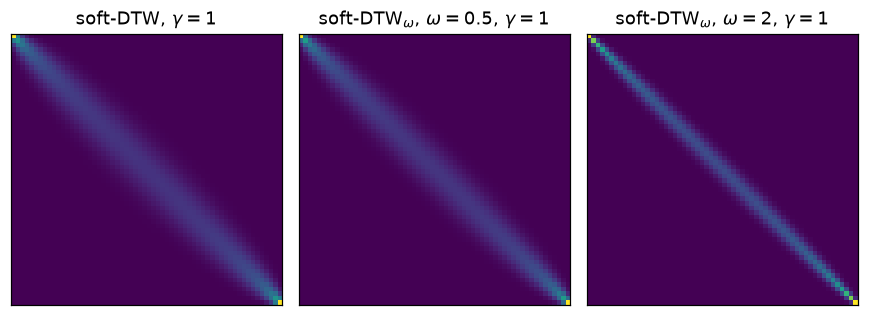

In [7]:
n = 60
z = np.zeros((n, 1))
fig, axes = plt.subplots(1, 3, figsize=(8, 3))
for ax, (title, kind, om) in zip(axes, [("soft-DTW", "dtw", 0.0),
                                         ("soft-DTW$_\\omega$, $\\omega=0.5$", "adtw", 0.5),
                                         ("soft-DTW$_\\omega$, $\\omega=2$", "adtw", 2.0)]):
    Cd, Cv, Ch = edge_costs(z, z, kind, omega=om)
    _, (Pd, Pv, Ph) = soft_dp(Cd, Cv, Ch, 1.0)
    ax.imshow((Pd + Pv + Ph)[1:, 1:], cmap="viridis")
    ax.set_title(title + ", $\\gamma=1$"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 2. Data
13 univariate datasets of the UCR archive, chosen to span domains, lengths (24 to 512) and numbers of classes (2 to 60). The series are z-normalised by the archive itself.

**Diagnosis** (`data_diagnosis.py`), over 200 random pairs $(x,y)$ of series of the same class:
* **lag**: the shift that best superimposes the two series (maximum of the cross-correlation), in % of the length;
* **DTW gain** $=1-\mathrm{dtw}(x,y)/\|x-y\|^2$: the share of their Euclidean distance that is due to misalignment.

In [8]:
diag = pd.read_csv("results/data_diagnosis.csv")
diag[["dataset", "n_train", "n_test", "length", "n_classes", "mean_abs_mean", "mean_std",
      "lag_median_pct", "lag_p90_pct", "dtw_gain_median"]].round(3)

,dataset,n_train,n_test,length,n_classes,mean_abs_mean,mean_std,lag_median_pct,lag_p90_pct,dtw_gain_median
0,ItalyPowerDemand,67,1029,24,2,0.0,0.979,0.000,8.333,0.484
1,SyntheticControl,300,300,60,6,0.0,0.992,3.333,35.167,0.759
2,TwoLeadECG,23,1139,82,2,0.0,0.994,2.439,6.098,0.896
3,ECG200,100,100,96,2,0.0,0.995,2.083,19.792,0.794
4,MedicalImages,381,760,99,10,0.0,0.995,1.010,8.182,0.784
5,CBF,30,900,128,3,0.0,0.996,4.688,25.781,0.850
6,ECGFiveDays,23,861,136,2,0.0,0.996,1.471,3.676,0.901
7,Plane,105,105,144,7,0.0,0.997,0.000,0.694,0.897
8,GunPoint,50,150,150,2,0.0,0.997,0.667,5.333,0.767
9,ArrowHead,36,175,251,3,0.0,0.998,0.000,0.000,0.847


Two regimes appear. CBF, Trace, SyntheticControl or ECG200 contain large **global shifts** (10% of the pairs shifted by 15–35% of the length). Coffee, ArrowHead or Plane are globally aligned (lag 0), yet DTW still removes most of the Euclidean cost: their variability is made of **local** accelerations, which a global shift cannot fix but warping can. Below, one pair of each kind with its DTW alignment.

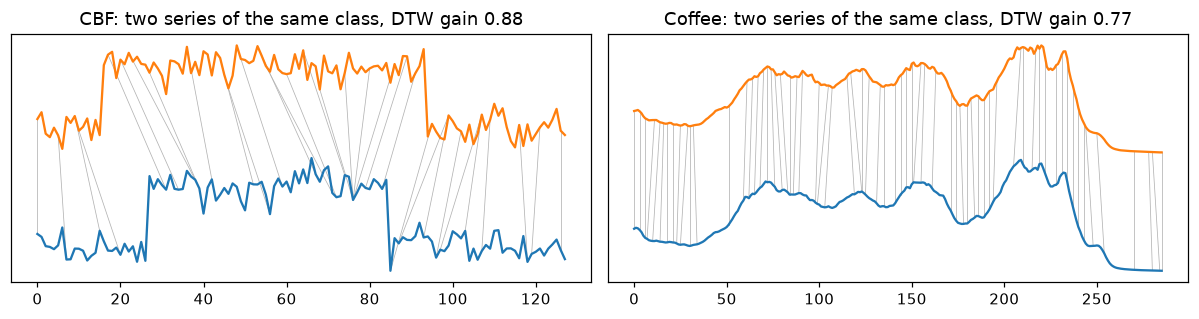

In [9]:
from tslearn.datasets import UCR_UEA_datasets
ucr = UCR_UEA_datasets(use_cache=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, name in zip(axes, ["CBF", "Coffee"]):
    X, y, _, _ = ucr.load_dataset(name)
    idx = np.where(y == y[0])[0][:2]
    a, b = X[idx[0], :, 0], X[idx[1], :, 0] + 4
    A, _ = dtw_path(a, b - 4)
    for i, j in zip(*np.nonzero(A)):
        if (i + j) % 6 == 0:
            ax.plot([i, j], [a[i], b[j]], color="0.7", lw=0.5)
    ax.plot(a, color="C0"); ax.plot(b, color="C1")
    gain = 1 - dtw(a, b - 4) / ((a - b + 4) ** 2).sum()
    ax.set_title(f"{name}: two series of the same class, DTW gain {gain:.2f}"); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 3. Experiments
Each experiment follows the paper's protocol and adds soft-DTW$_\omega$ ($\omega\in\{0.1,1\}$) on the same draws and initialisations. Datasets: 12 for barycenters and nearest centroid, 10 for $k$-means, 13 for forecasting (the paper used 79).

### 3.1 Barycenters and $k$-means (Tables 1–2 of the paper; Table 2 of the report)
For each dataset, 10 random draws of 10 series of one class; all methods start from the same initialisation (random or Euclidean mean) and are scored with the **hard DTW loss** (the objective DBA minimises). $k$-means: $k$ = number of classes, 3 random initialisations and a Euclidean $k$-means one.

Scripts: `exp_barycenters.py`, `exp_kmeans.py` (soft-DTW, DBA, subgradient), `exp_barycenters_omega.py`, `exp_kmeans_omega.py` (soft-DTW$_\omega$).

The table gives the **percentage of datasets on which soft-DTW (resp. soft-DTW$_\omega$, $\omega=0.1$ / $\omega=1$) reaches a lower loss** than DBA / the subgradient method, with the paper's value in parentheses.

In [10]:
bary = pd.read_csv("results/barycenters.csv")
km = pd.read_csv("results/kmeans.csv")
bary_om = pd.concat([pd.read_csv("results/barycenters_omega.csv"),
                     pd.read_csv("results/barycenters_omega_extra.csv")])
bary_om = bary_om[bary_om.method == "soft-DTW_omega"].rename(columns={"train_loss": "loss"})
km_om = pd.read_csv("results/kmeans_omega.csv")

PAPER = {  # Tables 1 and 2 of the paper (79 datasets)
    ("Barycenters", "DBA", "random"): [41, 94, 100, 97], ("Barycenters", "DBA", "euclidean"): [4, 47, 80, 90],
    ("Barycenters", "subgradient", "random"): [96, 97, 97, 97], ("Barycenters", "subgradient", "euclidean"): [35, 72, 92, 97],
    ("k-means", "DBA", "random"): [16, 25, 60, 77], ("k-means", "DBA", "euclidean"): [29, 24, 55, 69],
    ("k-means", "subgradient", "random"): [42, 58, 76, 96], ("k-means", "subgradient", "euclidean"): [46, 50, 66, 84]}

def per_dataset(df, val, **cond):
    for k, v in cond.items():
        df = df[df[k] == v]
    return df.groupby("dataset")[val].mean()   # mean over draws / seeds

def win_rate(a, b):
    return round(100 * (a < b.reindex(a.index)).mean())

rows = []
for task, df, df_om, val in [("Barycenters", bary, bary_om, "loss"), ("k-means", km, km_om, "energy")]:
    for method in ["soft-DTW", "soft-DTW_omega"]:
        for ref in ["DBA", "subgradient"]:
            for init in ["random", "euclidean"]:
                r = per_dataset(df, val, method=ref, init=init)
                row = {"task": task, "method": method, "compared with": f"{ref}, {init} init"}
                for k, g in enumerate(GAMMAS):
                    if method == "soft-DTW":
                        ours = win_rate(per_dataset(df, val, method=method, gamma=g, init=init), r)
                        row[f"gamma={g}"] = f"{ours} ({PAPER[task, ref, init][k]})"
                    else:
                        w = [win_rate(per_dataset(df_om, val, gamma=g, omega=om, init=init), r) for om in (0.1, 1.0)]
                        row[f"gamma={g}"] = f"{w[0]} / {w[1]}"
                rows.append(row)
pd.DataFrame(rows).set_index(["task", "method", "compared with"])

gamma=1.0  gamma=0.1  \
task        method         compared with                                      
Barycenters soft-DTW       DBA, random init              58 (41)    92 (94)   
                           DBA, euclidean init             8 (4)    25 (47)   
                           subgradient, random init      75 (96)   100 (97)   
                           subgradient, euclidean init   17 (35)    75 (72)   
            soft-DTW_omega DBA, random init              58 / 58    83 / 58   
                           DBA, euclidean init             8 / 8     17 / 8   
                           subgradient, random init      75 / 83  100 / 100   
                           subgradient, euclidean init   17 / 17    50 / 17   
k-means     soft-DTW       DBA, random init              10 (16)    50 (25)   
                           DBA, euclidean init           10 (29)    10 (24)   
                           subgradient, random init      20 (42)    60 (58)   
                           subgradient, euclidean init   10 (46)    10 (50)   
            soft-DTW_omega DBA, random init              10 / 10    40 / 10   
                           DBA, euclidean init            10 / 0     10 / 0   
                           subgradient, random init      20 / 20    70 / 30   
                           subgradient, euclidean init    10 / 0     20 / 0   

                                                       gamma=0.01 gamma=0.001  
task        method         compared with                                       
Barycenters soft-DTW       DBA, random init             100 (100)    100 (97)  
                           DBA, euclidean init            75 (80)    100 (90)  
                           subgradient, random init      100 (97)    100 (97)  
                           subgradient, euclidean init    92 (92)    100 (97)  
            soft-DTW_omega DBA, random init               83 / 58     83 / 58  
                           DBA, euclidean init              8 / 8       8 / 8  
                           subgradient, random init     100 / 100   100 / 100  
                           subgradient, euclidean init    58 / 17     58 / 17  
k-means     soft-DTW       DBA, random init               70 (60)     90 (77)  
                           DBA, euclidean init            60 (55)     90 (69)  
                           subgradient, random init      100 (76)     90 (96)  
                           subgradient, euclidean init    90 (66)    100 (84)  
            soft-DTW_omega DBA, random init               40 / 20     40 / 20  
                           DBA, euclidean init             10 / 0      20 / 0  
                           subgradient, random init       60 / 30     60 / 30  
                           subgradient, euclidean init     10 / 0      20 / 0

**Magnitudes and costs**, which the paper does not report (median over datasets of the loss ratio to DBA, and computing time relative to DBA):

In [11]:
for init in ["random", "euclidean"]:
    dba = per_dataset(bary, "loss", method="DBA", init=init)
    ratios = {g: (per_dataset(bary, "loss", method="soft-DTW", gamma=g, init=init) / dba) for g in GAMMAS}
    print(f"barycenters, {init:9s} init: median soft-DTW / DBA loss ratio",
          {g: round(r.median(), 2) for g, r in ratios.items()})
r = per_dataset(bary, "loss", method="soft-DTW", gamma=0.1, init="random") / per_dataset(bary, "loss", method="DBA", init="random")
print("  best case (random init, gamma=0.1):", r.idxmin(), round(r.min(), 2))
for init in ["random", "euclidean"]:
    dba = per_dataset(km, "energy", method="DBA", init=init)
    print(f"k-means,     {init:9s} init: median soft-DTW / DBA energy ratio",
          {g: round((per_dataset(km, "energy", method="soft-DTW", gamma=g, init=init) / dba).median(), 2) for g in GAMMAS})
t_dba = bary[bary.method == "DBA"].time.median()
print("\nbarycenter time / DBA:", {g: round(bary[(bary.method == "soft-DTW") & (bary.gamma == g)].time.median() / t_dba, 1) for g in GAMMAS})
t_dba = km[km.method == "DBA"].time.median()
print("k-means time / DBA:   ", {g: round(km[(km.method == "soft-DTW") & (km.gamma == g)].time.median() / t_dba, 1) for g in GAMMAS})

barycenters, random    init: median soft-DTW / DBA loss ratio {1.0: np.float64(0.93), 0.1: np.float64(0.85), 0.01: np.float64(0.86), 0.001: np.float64(0.95)}
barycenters, euclidean init: median soft-DTW / DBA loss ratio {1.0: np.float64(1.68), 0.1: np.float64(1.01), 0.01: np.float64(0.97), 0.001: np.float64(0.97)}
  best case (random init, gamma=0.1): Plane 0.26
k-means,     random    init: median soft-DTW / DBA energy ratio {1.0: np.float64(1.29), 0.1: np.float64(1.04), 0.01: np.float64(0.97), 0.001: np.float64(0.97)}
k-means,     euclidean init: median soft-DTW / DBA energy ratio {1.0: np.float64(1.61), 0.1: np.float64(1.15), 0.01: np.float64(1.0), 0.001: np.float64(0.98)}

barycenter time / DBA: {1.0: np.float64(3.9), 0.1: np.float64(6.9), 0.01: np.float64(10.2), 0.001: np.float64(14.1)}
k-means time / DBA:    {1.0: np.float64(4.5), 0.1: np.float64(7.4), 0.01: np.float64(10.3), 0.001: np.float64(15.6)}


**Soft-DTW$_\omega$ against soft-DTW.** `exp_barycenters_omega.py` recomputes soft-DTW ($\gamma=0.1$, $0.01$) on the same draws, so the two can be compared directly (median over datasets of the loss ratio to soft-DTW with $\gamma=0.01$, and of the computing time):

In [12]:
both = pd.concat([pd.read_csv("results/barycenters_omega.csv"), pd.read_csv("results/barycenters_omega_extra.csv")])
both["omega"] = both.omega.fillna(0)
for init in ["random", "euclidean"]:
    d = both[both.init == init]
    ref = per_dataset(d, "train_loss", method="soft-DTW", gamma=0.01)
    t_ref = d[(d.method == "soft-DTW") & (d.gamma == 0.01)].groupby("dataset").time.median()
    print(f"{init} init")
    for (m, g, om), grp in d[d.method != "DBA"].groupby(["method", "gamma", "omega"]):
        ratio = grp.groupby("dataset").train_loss.mean() / ref
        t_ratio = (grp.groupby("dataset").time.median() / t_ref).median()
        print(f"   {m:15s} gamma={g:<6} omega={om:<4}  loss ratio {ratio.median():.2f}"
              f"  (lower on {(ratio < 1).sum():2d}/12)   time ratio {t_ratio:.2f}")

random init
   soft-DTW        gamma=0.01   omega=0.0   loss ratio 1.00  (lower on  0/12)   time ratio 1.00
   soft-DTW        gamma=0.1    omega=0.0   loss ratio 0.95  (lower on  9/12)   time ratio 0.91
   soft-DTW_omega  gamma=0.001  omega=0.1   loss ratio 0.98  (lower on  7/12)   time ratio 0.89
   soft-DTW_omega  gamma=0.001  omega=1.0   loss ratio 0.99  (lower on  6/12)   time ratio 0.38
   soft-DTW_omega  gamma=0.01   omega=0.1   loss ratio 0.96  (lower on  7/12)   time ratio 0.91
   soft-DTW_omega  gamma=0.01   omega=1.0   loss ratio 1.00  (lower on  6/12)   time ratio 0.31
   soft-DTW_omega  gamma=0.1    omega=0.1   loss ratio 0.92  (lower on  9/12)   time ratio 0.75
   soft-DTW_omega  gamma=0.1    omega=1.0   loss ratio 1.02  (lower on  6/12)   time ratio 0.29
   soft-DTW_omega  gamma=1.0    omega=0.1   loss ratio 1.06  (lower on  3/12)   time ratio 0.36
   soft-DTW_omega  gamma=1.0    omega=1.0   loss ratio 1.02  (lower on  5/12)   time ratio 0.26
euclidean init
   soft-DTW  

Small $\gamma$ beats DBA almost always and $\gamma=1$ rarely, as in the paper, but the gains are large only from a random start; with $\gamma=0.001$ a barycenter costs about $14\times$ DBA. Soft-DTW$_\omega$ helps from a random start ($\gamma=\omega=0.1$: lower loss and faster), but from the Euclidean mean and in $k$-means plain soft-DTW is best: as $\gamma\to0$, soft-DTW tends to the DTW loss used for scoring, whereas soft-DTW$_\omega$ tends to DTW plus a warping penalty, a different objective.

**Qualitative figures** (paper Figs. 4–6, generated by `make_figures.py`):

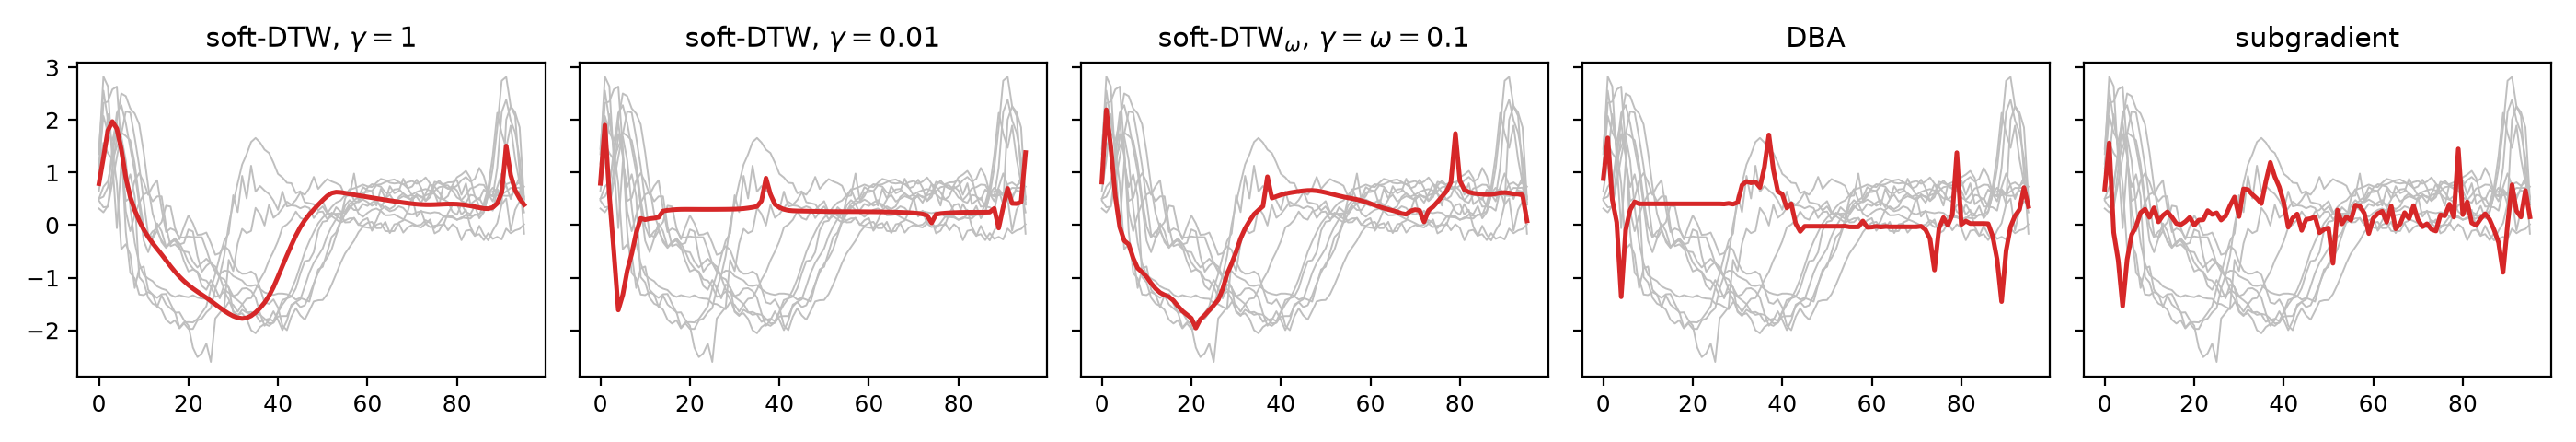

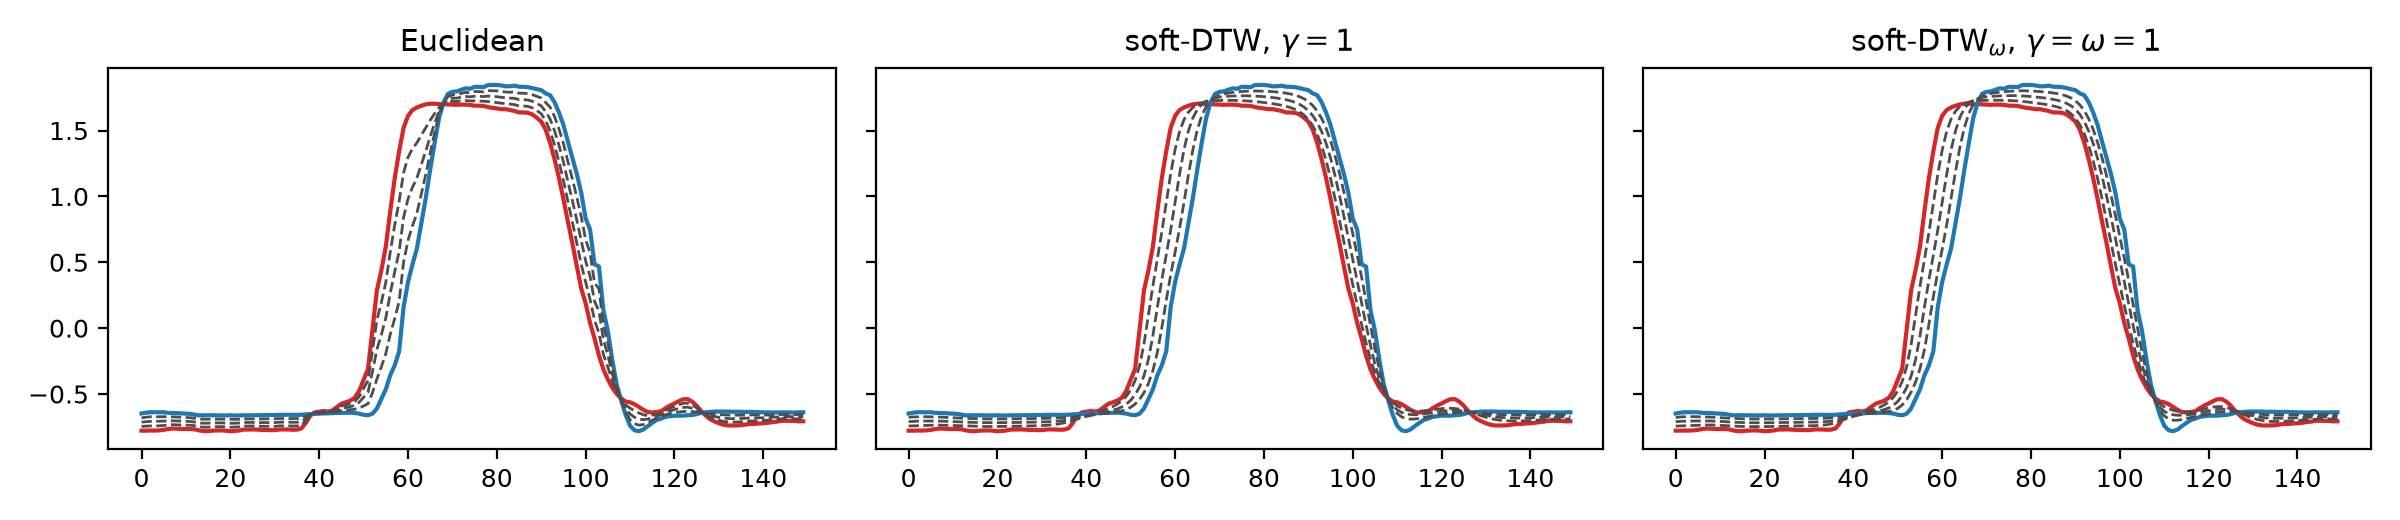

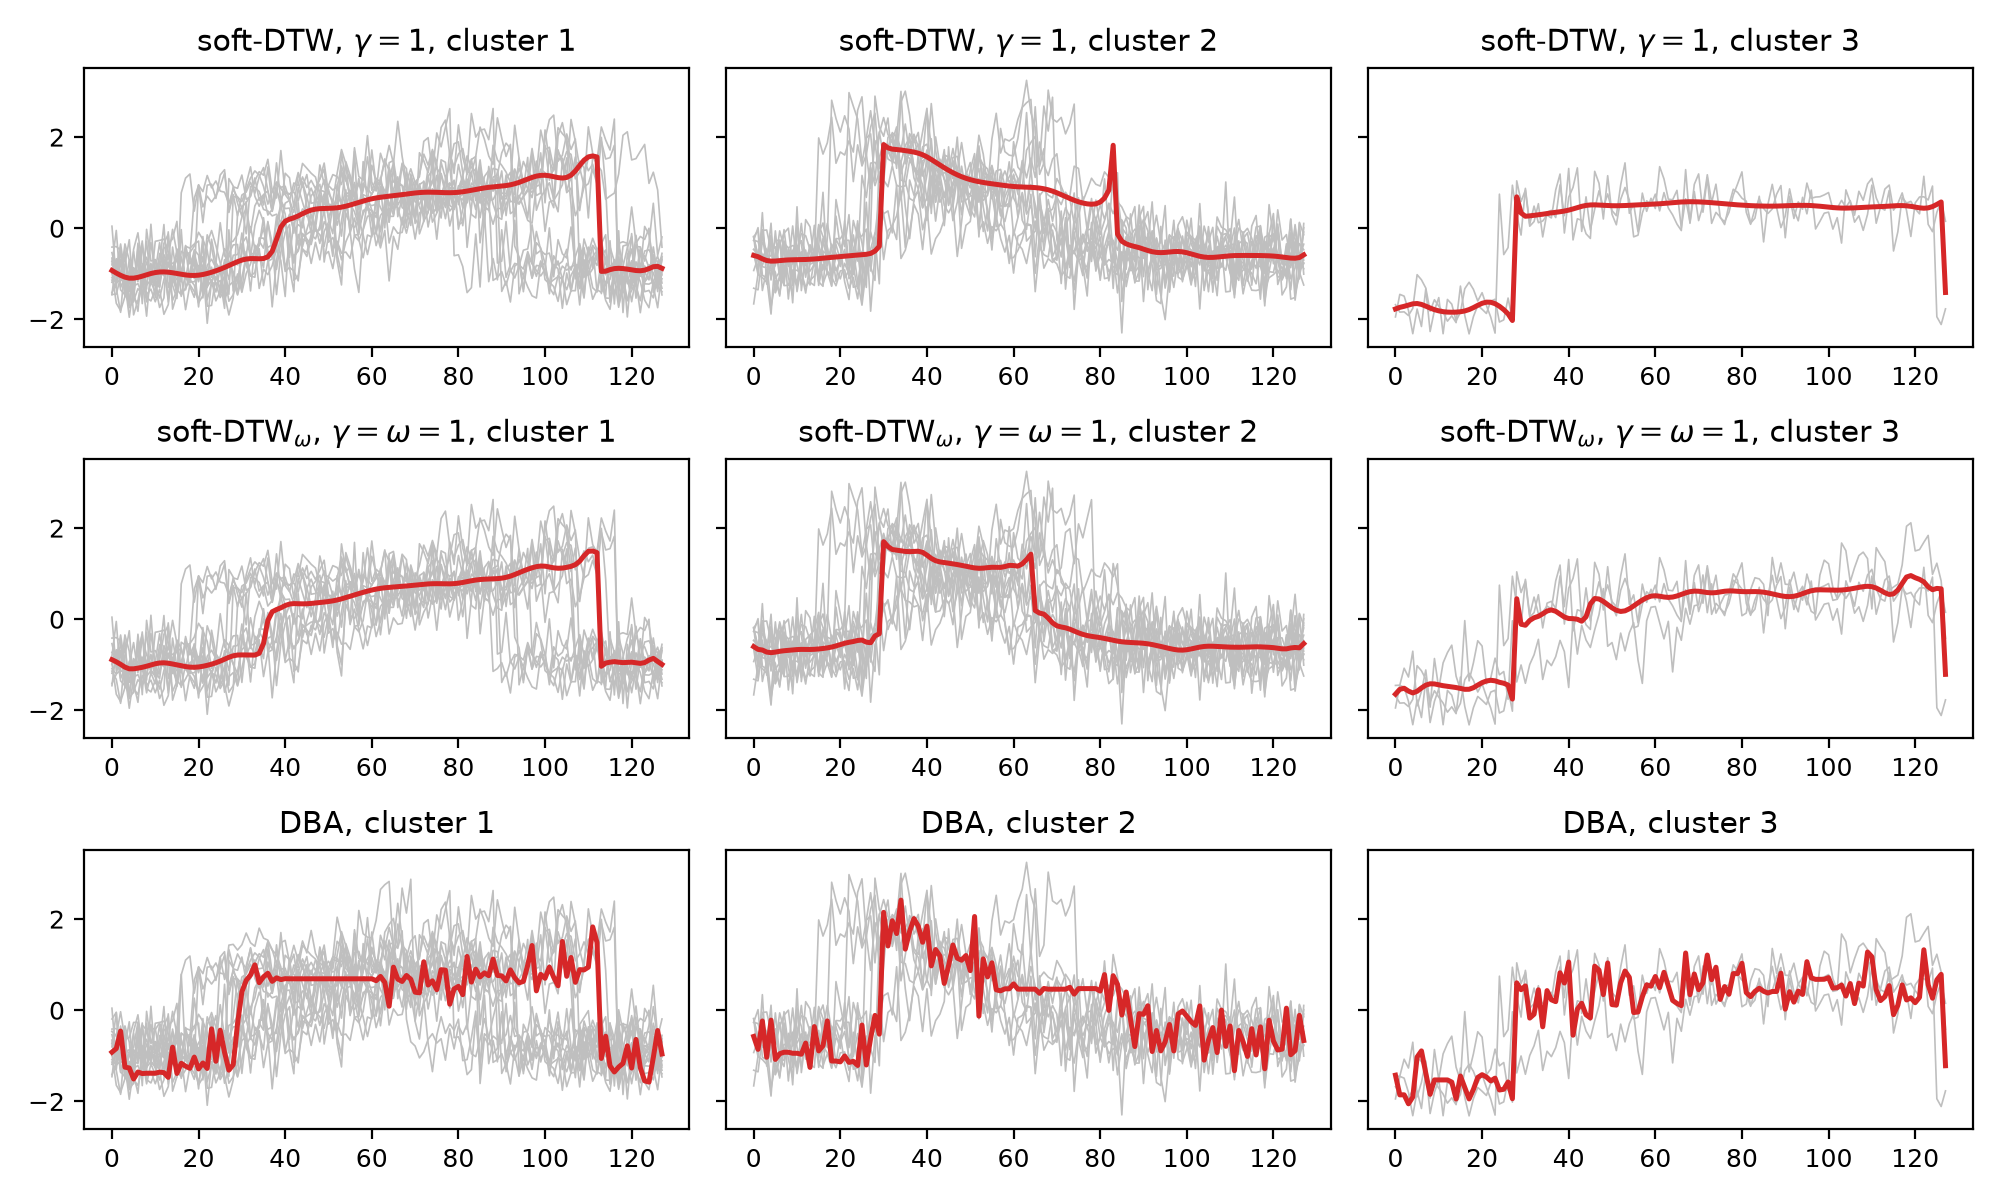

In [13]:
for f in ["barycenters_ECG200.png", "interpolation_GunPoint.png", "kmeans_CBF.png"]:
    display(Image(f"figures/{f}", width=900))

### 3.2 Nearest-centroid classification (Fig. 7 of the paper)
Each class is represented by the barycenter of its training series, and a new series gets the class of the closest centroid. Train and test sets are pooled and split 50/25/25 (3 random stratified splits); centroids start from the class Euclidean mean; $\gamma$ (15 values in $[10^{-3},10]$) and $\omega\in\{0.1,1\}$ are chosen on validation. Each method assigns with its own discrepancy (hard DTW for DBA).

Scripts: `exp_classification.py`, `exp_classification_omega.py`.

soft-DTW >= DBA on 83% of the datasets (paper: 75%)
soft-DTW_omega >= DBA on 75%;  soft-DTW_omega better than soft-DTW on 6 datasets, worse on 4
mean accuracy: {'DBA': 0.811, 'soft-DTW': 0.863, 'soft-DTW_omega': 0.85}


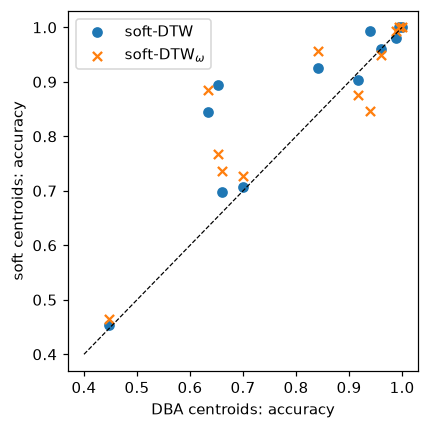

method,DBA,soft-DTW,soft-DTW_omega
dataset,,,
ArrowHead,0.660,0.698,0.736
CBF,0.960,0.960,0.948
Coffee,1.000,1.000,1.000
ECG200,0.700,0.707,0.727
ECGFiveDays,0.633,0.845,0.885
GunPoint,0.653,0.893,0.767
ItalyPowerDemand,0.841,0.926,0.957
MedicalImages,0.446,0.453,0.464
Plane,0.994,1.000,1.000


In [14]:
cl = pd.concat([pd.read_csv("results/classification.csv"), pd.read_csv("results/classification_omega.csv")])
acc = (cl[cl.method.isin(["DBA", "soft-DTW", "soft-DTW_omega"])]
       .groupby(["dataset", "method"]).acc.mean().unstack())
print(f"soft-DTW >= DBA on {100 * (acc['soft-DTW'] >= acc['DBA']).mean():.0f}% of the datasets (paper: 75%)")
print(f"soft-DTW_omega >= DBA on {100 * (acc['soft-DTW_omega'] >= acc['DBA']).mean():.0f}%;  "
      f"soft-DTW_omega better than soft-DTW on {(acc['soft-DTW_omega'] > acc['soft-DTW']).sum()} datasets, "
      f"worse on {(acc['soft-DTW_omega'] < acc['soft-DTW']).sum()}")
print("mean accuracy:", acc.mean().round(3).to_dict())

fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(acc["DBA"], acc["soft-DTW"], label="soft-DTW")
ax.scatter(acc["DBA"], acc["soft-DTW_omega"], marker="x", label="soft-DTW$_\\omega$")
ax.plot([0.4, 1], [0.4, 1], "k--", lw=0.8)
ax.set_xlabel("DBA centroids: accuracy"); ax.set_ylabel("soft centroids: accuracy"); ax.legend()
plt.tight_layout(); plt.show()
acc.round(3)

### 3.3 Multistep-ahead forecasting (Table 3 of the paper)
An MLP (one hidden layer of 256 sigmoid units, Adam, 400 epochs) sees the first 60% of each series and predicts the remaining 40%. It is trained with the Euclidean loss, soft-DTW or soft-DTW$_\omega$, either from random weights or from the network already trained with the Euclidean loss. The test forecasts are evaluated with DTW and with the Euclidean distance; on each dataset the losses are ranked (1 = best).

Scripts: `exp_forecast.py` (Euclidean and soft-DTW), `exp_forecast_omega.py` and `exp_forecast_omega_gammas.py` (soft-DTW$_\omega$).

Rows soft-DTW$_\omega$: rank obtained when soft-DTW$_\omega$ ($\omega=0.1$ / $\omega=1$) replaces soft-DTW with the same $\gamma$.

In [15]:
fc = pd.read_csv("results/forecast.csv"); fc["gamma"] = fc.gamma.fillna(0)
fo = pd.read_csv("results/forecast_omega.csv")
fo = fo[fo.model.str.startswith("soft-DTW_omega")].assign(gamma=0.01, omega=lambda d: d.model.str.split().str[-1].astype(float))
fo = pd.concat([fo, pd.read_csv("results/forecast_omega_gammas.csv")])

PAPER_FC = {("dtw", "random"): [3.46, 3.55, 3.33, 2.79, 1.87], ("dtw", "euclidean"): [4.21, 3.96, 3.42, 2.12, 1.29],
            ("euclid", "random"): [1.05, 2.41, 3.42, 4.13, 3.99], ("euclid", "euclidean"): [1.70, 2.99, 3.38, 3.64, 3.29]}

def five_models(metric, init):
    t = fc[fc.init == init]
    m = pd.DataFrame({"Euclidean": t[t.model == "Euclidean"].set_index("dataset")[metric]})
    for g in GAMMAS:
        m[g] = t[(t.model == "soft-DTW") & (t.gamma == g)].set_index("dataset")[metric]
    return m

rows = []
for metric in ["dtw", "euclid"]:
    for init in ["random", "euclidean"]:
        m = five_models(metric, init)
        ranks = m.rank(axis=1).mean()
        rows.append({"metric": metric, "init": init, "loss": "soft-DTW",
                     **{str(c): f"{ranks[c]:.2f} ({p:.2f})" for c, p in zip(m.columns, PAPER_FC[metric, init])}})
        row = {"metric": metric, "init": init, "loss": "soft-DTW_omega (0.1 / 1)", "Euclidean": ""}
        for g in GAMMAS:
            cells = []
            for om in (0.1, 1.0):
                swapped = m.copy()
                swapped[g] = fo[(fo.init == init) & (fo.gamma == g) & (fo.omega == om)].set_index("dataset")[metric]
                cells.append(f"{swapped.rank(axis=1).mean()[g]:.2f}")
            row[str(g)] = " / ".join(cells)
        rows.append(row)
pd.DataFrame(rows).set_index(["metric", "init", "loss"])

Euclidean          1.0  \
metric init      loss                                                 
dtw    random    soft-DTW                  3.69 (3.46)  3.92 (3.55)   
                 soft-DTW_omega (0.1 / 1)               3.92 / 3.92   
       euclidean soft-DTW                  3.92 (4.21)  4.46 (3.96)   
                 soft-DTW_omega (0.1 / 1)               4.46 / 4.08   
euclid random    soft-DTW                  1.31 (1.05)  1.69 (2.41)   
                 soft-DTW_omega (0.1 / 1)               1.69 / 1.77   
       euclidean soft-DTW                  2.77 (1.70)  1.62 (2.99)   
                 soft-DTW_omega (0.1 / 1)               1.62 / 1.69   

                                                   0.1         0.01  \
metric init      loss                                                 
dtw    random    soft-DTW                  2.31 (3.33)  2.23 (2.79)   
                 soft-DTW_omega (0.1 / 1)  2.15 / 3.00  2.08 / 3.31   
       euclidean soft-DTW                  2.85 (3.42)  2.08 (2.12)   
                 soft-DTW_omega (0.1 / 1)  2.46 / 3.15  2.38 / 2.92   
euclid random    soft-DTW                  3.46 (3.42)  4.00 (4.13)   
                 soft-DTW_omega (0.1 / 1)  3.31 / 2.00  3.15 / 1.92   
       euclidean soft-DTW                  2.38 (3.38)  3.77 (3.64)   
                 soft-DTW_omega (0.1 / 1)  2.23 / 2.38  2.77 / 2.38   

                                                 0.001  
metric init      loss                                   
dtw    random    soft-DTW                  2.85 (1.87)  
                 soft-DTW_omega (0.1 / 1)  2.08 / 3.38  
       euclidean soft-DTW                  1.69 (1.29)  
                 soft-DTW_omega (0.1 / 1)  2.46 / 2.92  
euclid random    soft-DTW                  4.54 (3.99)  
                 soft-DTW_omega (0.1 / 1)  3.23 / 1.85  
       euclidean soft-DTW                  4.46 (3.29)  
                 soft-DTW_omega (0.1 / 1)  2.62 / 2.23

**Magnitudes**: median test error of soft-DTW$_\omega$ relative to soft-DTW with the same $\gamma$ and initialisation ($\omega=0.1$ / $\omega=1$; below 1 is better), and the failure cases of soft-DTW trained from random weights.

In [16]:
for init in ["random", "euclidean"]:
    for metric in ["dtw", "euclid"]:
        cells = []
        for g in GAMMAS:
            s = fc[(fc.init == init) & (fc.model == "soft-DTW") & (fc.gamma == g)].set_index("dataset")[metric]
            r = [(fo[(fo.init == init) & (fo.gamma == g) & (fo.omega == om)].set_index("dataset")[metric] / s).median()
                 for om in (0.1, 1.0)]
            cells.append(f"gamma={g}: {r[0]:.2f} / {r[1]:.2f}")
        print(f"{init:9s} {metric:6s}  " + "   ".join(cells))

print()
for name in ["ShapesAll", "Coffee", "Plane"]:
    e = fc[(fc.dataset == name) & (fc.model == "Euclidean") & (fc.init == "random")].iloc[0]
    s = fc[(fc.dataset == name) & (fc.model == "soft-DTW") & (fc.init == "random") & (fc.gamma == 0.001)].iloc[0]
    w = fo[(fo.dataset == name) & (fo.init == "random") & (fo.gamma == 0.001) & (fo.omega == 1.0)].iloc[0]
    print(f"{name:9s} (random init, gamma=0.001)  test DTW / Euclidean error:  Euclidean loss {e.dtw:.2f} / {e.euclid:.1f}"
          f"   soft-DTW {s.dtw:.2f} / {s.euclid:.1f}   soft-DTW_omega (omega=1) {w.dtw:.2f} / {w.euclid:.1f}")

random    dtw     gamma=1.0: 1.00 / 0.99   gamma=0.1: 1.00 / 1.09   gamma=0.01: 0.98 / 1.06   gamma=0.001: 1.00 / 1.07
random    euclid  gamma=1.0: 0.99 / 0.92   gamma=0.1: 0.93 / 0.73   gamma=0.01: 0.68 / 0.44   gamma=0.001: 0.70 / 0.33
euclidean dtw     gamma=1.0: 1.00 / 0.95   gamma=0.1: 0.99 / 1.01   gamma=0.01: 1.01 / 1.07   gamma=0.001: 1.03 / 1.07
euclidean euclid  gamma=1.0: 1.00 / 1.00   gamma=0.1: 0.99 / 0.97   gamma=0.01: 0.98 / 0.90   gamma=0.001: 0.92 / 0.85

ShapesAll (random init, gamma=0.001)  test DTW / Euclidean error:  Euclidean loss 9.31 / 43.7   soft-DTW 6.27 / 154.1   soft-DTW_omega (omega=1) 8.22 / 51.0
Coffee    (random init, gamma=0.001)  test DTW / Euclidean error:  Euclidean loss 0.45 / 1.2   soft-DTW 1.44 / 91.8   soft-DTW_omega (omega=1) 0.44 / 1.2
Plane     (random init, gamma=0.001)  test DTW / Euclidean error:  Euclidean loss 0.35 / 1.6   soft-DTW 0.69 / 33.4   soft-DTW_omega (omega=1) 0.35 / 1.6


Each loss wins on its own metric, as in the paper. Trained from random weights, soft-DTW can degenerate: on ShapesAll it predicts an almost flat line with isolated spikes that DTW still scores better than the Euclidean forecast, because a single point can be matched with a whole segment. The warping penalty removes these failures and trades a little DTW for a much lower Euclidean error.

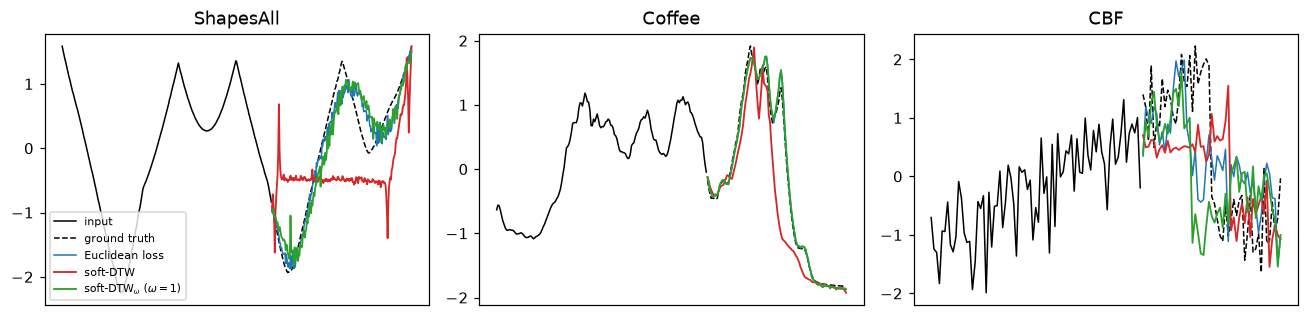

In [17]:
z = np.load("results/forecast_omega_examples.npz")
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, (name, k) in zip(axes, [("ShapesAll", 0), ("Coffee", 3), ("CBF", 1)]):
    inp, truth = z[f"{name}/input"][k], z[f"{name}/truth"][k]
    t_in, t_out = np.arange(len(inp)), np.arange(len(inp), len(inp) + len(truth))
    ax.plot(t_in, inp, "k", lw=1, label="input")
    ax.plot(t_out, truth, "k--", lw=1, label="ground truth")
    ax.plot(t_out, z[f"{name}/Euclidean"][k], color="C0", lw=1, label="Euclidean loss")
    ax.plot(t_out, z[f"{name}/soft-DTW"][k], color="C3", lw=1.2, label="soft-DTW")
    ax.plot(t_out, z[f"{name}/soft-DTW_omega 1"][k], color="C2", lw=1.2, label="soft-DTW$_\\omega$ ($\\omega=1$)")
    ax.set_title(name); ax.set_xticks([])
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 4. Conclusion
* Our implementation matches the definition of soft-DTW exactly (brute force) and its gradient (finite differences); a hand-written backward is essential (Numba is ~65× faster than the same Python code and orders of magnitude faster than autograd).
* The paper's claims hold on our 10–13 datasets: soft-DTW with a small $\gamma$ beats DBA as a barycenter and in $k$-means, gives better nearest centroids, and each forecasting loss wins on its own metric.
* The magnitudes nuance them: large gains only from poor initialisations, a 14–16× overhead for $\gamma=0.001$, and unstable forecasting from scratch with degenerate predictions that DTW scores well.
* Soft-DTW$_\omega$, which charges $\omega$ for every time-stretching step, removes these forecasting failures and controls the trade-off between shape and timing; it improves barycenters from poor initialisations, but not from a good one, and does not improve $k$-means or nearest-centroid classification.